<!-- <img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;"> -->
![MUML_header](MUML_header.svg)

### Optimization with autograd

Imagine you are a data scientist for a new logistics company. Your company needs to build a central distribution hub to serve several major cities. Your task is to find the single geographic point for the new hub that minimizes the total straight-line distance to all the cities it serves. However, not all the cities are equal: some are megacities while others are small towns. Our hub should probably be closer to the megacities.

 For a set of city coordinates c₁, c₂, ..., cₙ, we want to find the point p = (x, y) that minimizes the distance to all cities weighted by their population. It can be summarized in  the following function
$$dis(p)=\sum_i w_i * ||p - c_i||_2$$
where $||\ldots||_2$ is the standard Euclidean distance.
The derivative of this function is not simple to calculate by hand, especially for many cities. This is a perfect job for autograd.
Your task is, given a set of 2D coordinates for several cities and their population, to use PyTorch to find the optimal coordinates (x, y) for the distribution hub.

Location and population of the cities:
* City 1 - (0.0, 10.0) - 250,000 inhabitants
* City 2 - (1.0, 1.0) - 100,000 inhabitants
* City 3 - (12.0, 2.0) - 80,000 inhabitants
* City 4 - (15.0, 11.0) - 400,000 inhabitants
* City 5 - (8.0, 15.0) - 1,500 inhabitants
* City 6 - (5.0, 7.0) - 30,000 inhabitants


**Intuition**:
1. You should start by selecting a random point to locate the hub and calculating the function value at this point (without loops). 
2. With the gradient of the function at that point, can you know if the optimal point should have a bigger or a smaller value in x? And in y?
3. Move you solution a bit in those directions
4. Repeat the previous steps until you get a stable solution (or a given number of iterations)

**Questions**
1. What happens if you change the initial point to locate the hub? Try the following alternatives:
   * Random point
   * Centroid of the data
   * The exact location of one of the cities
   * A point outside the bounds of the data
2. What happens if you change the quantity you move your solution at each step (step 3 of intuition)? Try the following alternatives:
   * Very small quantity
   * Small quantity
   * Large quantity

Try using PyTorch for all the combinations from the above questions. With the best options, implement the optimization process using TensorFlow.
  
**Submission**
You have to create a short report (about two pages) evaluating the questions. It should contain graphs showing how the distance to the cities change and showing in the plane how the central distribution hub moves in between the cities. You also have to submit your code (not implemented with AI).

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import torch

I0000 00:00:1789506430.383886    6332 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789506430.471793    6332 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789506432.480523    6332 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


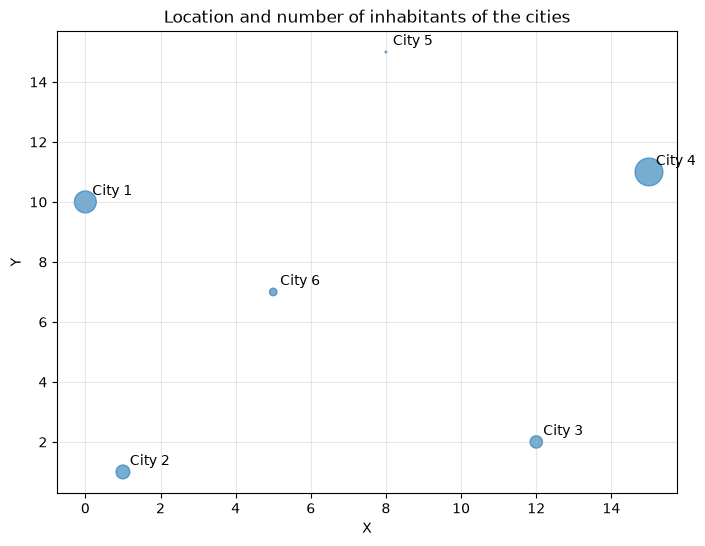

In [2]:
cities = ["City 1", "City 2", "City 3", "City 4", "City 5", "City 6"]

x = [0, 1, 12, 15, 8, 5]
y = [10, 1, 2, 11, 15, 7]

inhabitants = [250000, 100000, 80000, 400000, 1500, 30000]

#calculate city size for plot
city_size = [i / 1000 for i in inhabitants]

#plot
plt.figure(figsize=(8, 6))

plt.scatter(x, y, s=city_size, alpha=0.6)

for ciudad, xi, yi in zip(cities, x, y):
    plt.annotate(ciudad, (xi, yi), xytext=(5, 5),
                 textcoords="offset points")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Location and number of inhabitants of the cities")
plt.grid(True, alpha=0.3)

plt.show()


In [3]:
c = torch.tensor([[0.0, 10.0], [1.0, 1.0], [12.0, 2.0], [15.0, 11.0], [8.0, 15.0], [5.0, 7.0]]) #fixed(is not going to move) doesnt require grad 
w = torch.tensor([250000, 100000, 80000, 400000, 1500, 30000]) #fixed(population is not going to change) doesnt require grad 

def dis(p):
    distances = torch.sqrt(torch.sum((c - p) ** 2, dim=1))
    return sum(w*distances)

point = torch.tensor([6., 8.], requires_grad=True)
result = dis(point)
print(f'Result {point.data}: {result}')

Result tensor([6., 8.]): 6968273.5


In [4]:
#1. You should start by selecting a random point to locate the hub and calculating the function value at this point (without loops).
limit_x = max(x)
limit_y = max(y)
px = random.uniform(0, limit_x)
py = random.uniform(0, limit_y)
p = torch.tensor([px, py], requires_grad=True) #thing to optimize require grad 

result_p = dis(p)
print(f'Result {p.data}: {result_p}')

Result tensor([14.5312, 13.8482]): 8109831.5


In [5]:
# 2. With the gradient of the function at that point, can you know if the optimal point should have a bigger or a smaller value in x? And in y?
result_p.backward() #Calculate the derivatives of dis(p) with respect to the variables in p

print("Point:", p)
print("Gradient:", p.grad) #p.grad[0]=∂dis/∂x   p.grad[1]=∂dis/∂y

# If p.grad[0] > 0, increasing x increases dis, so we should decrease x to minimize it. -->same for y
# If p.grad[0] < 0, increasing x decreases dis, so we should increase x to minimize it. -->same for y
#to minimize we should go into gradient oposite direction

Point: tensor([14.5312, 13.8482], requires_grad=True)
Gradient: tensor([291776.7812, 623024.2500])


/home/ruthaltmno/FoundationsMachineLearning/Practices/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 302: Error loading CUDA libraries. GPU will not be used. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [6]:
#3. Move you solution a bit in those directions
learning_rate = 0.000001
print("Before:", p)
with torch.no_grad():
    p -= learning_rate * p.grad #move the point in the opposite direction of the gradient

# Reset the gradient
p.grad.zero_()
print("After:", p)

Before: tensor([14.5312, 13.8482], requires_grad=True)
After: tensor([14.2394, 13.2251], requires_grad=True)


In [7]:
#4. Repeat the previous steps until you get a stable solution (or a given number of iterations)
positions = []
loss_history = []

px = random.uniform(0, limit_x)
py = random.uniform(0, limit_y)
p = torch.tensor([px, py], requires_grad=True) #thing to optimize require grad 

for i in range(250):
    result_p = dis(p)
    result_p.backward()

    # Save current position
    positions.append(p.detach().clone())

    # Save objective value
    loss_history.append(result_p.detach().clone())

    with torch.no_grad():
        p -= learning_rate * p.grad

    p.grad.zero_()


In [8]:
positions = torch.stack(positions).detach().numpy()
loss_history = torch.stack(loss_history).detach().numpy()

final, position 12.711719512939453,10.049200057983398


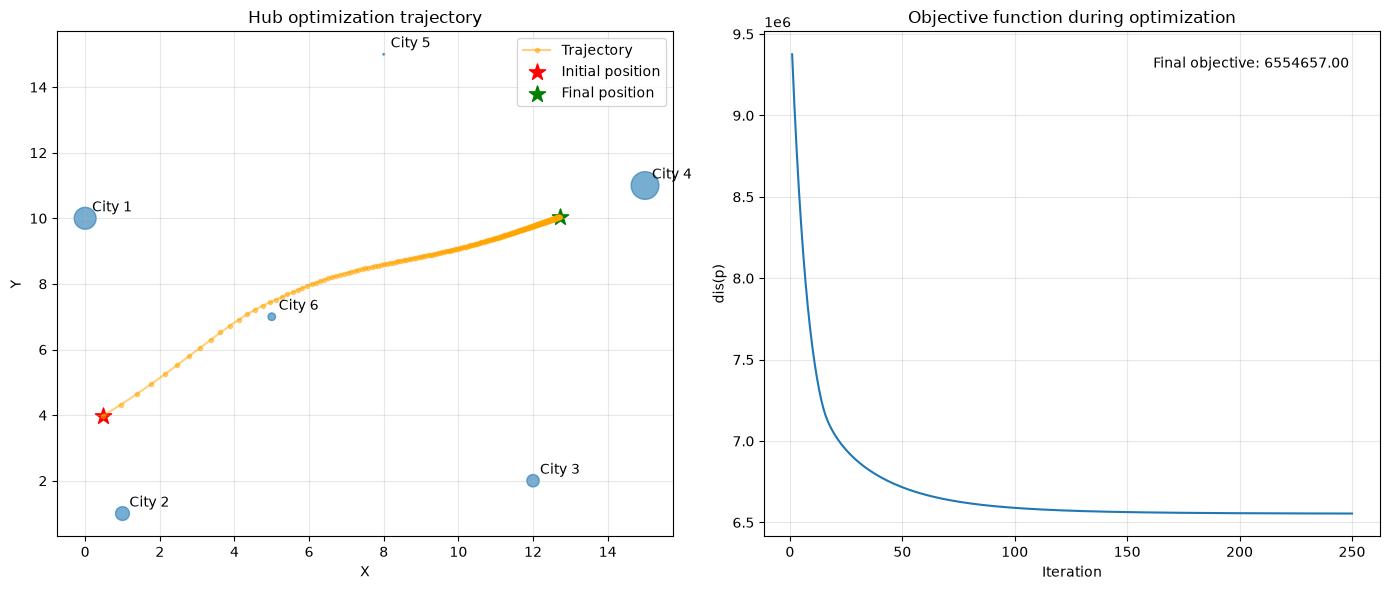

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

#hub trajectory
ax[0].scatter(x, y, s=city_size, alpha=0.6)
for ciudad, xi, yi in zip(cities, x, y):
    ax[0].annotate(ciudad, (xi, yi), xytext=(5, 5), textcoords="offset points")

ax[0].plot(positions[:, 0], positions[:, 1], marker="o", markersize=3, color="orange", alpha=0.5, label="Trajectory")
ax[0].scatter(positions[0, 0], positions[0, 1], marker="*", s=150, color="red", label="Initial position")
ax[0].scatter(positions[-1, 0], positions[-1, 1], marker="*", s=150, color="green", label="Final position")
print(f'final, position {positions[-1, 0]},{positions[-1, 1]}')

ax[0].set_xlabel("X")
ax[0].set_ylabel("Y")
ax[0].set_title("Hub optimization trajectory")
ax[0].grid(True, alpha=0.3)
ax[0].legend()

#objective function
ax[1].plot(range(1, len(loss_history) + 1), loss_history)
final_loss = loss_history[-1]
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("dis(p)")
ax[1].set_title("Objective function during optimization")
ax[1].grid(True, alpha=0.3)
ax[1].text(0.95, 0.95, f"Final objective: {final_loss:.2f}", transform=ax[1].transAxes, ha="right", va="top")

plt.tight_layout()
plt.show()

In [10]:
#make it into funtions 
def optimize(initial_point, learning_rate, iterations):
    positions = []
    loss_history = []
    distance_history = []

    p = torch.tensor(initial_point, requires_grad=True)

    for i in range(iterations):
        result_p = dis(p)
        result_p.backward()
    
        # Save current position
        positions.append(p.detach().clone())
    
        # Save objective value
        loss_history.append(result_p.detach().clone())

        distances = torch.sqrt(torch.sum((c - p) ** 2, dim=1))
        distance_history.append(distances.detach().clone())
    
        with torch.no_grad():
            p -= learning_rate * p.grad
    
        p.grad.zero_()
    
    return positions, loss_history, distance_history

def plot_optimization(positions, loss_history, distance_history, initial_name, learning_rate):

    positions = torch.stack(positions).detach().numpy()
    loss_history = torch.stack(loss_history).detach().numpy()
    distance_history = torch.stack(distance_history).detach().numpy()

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    #hub trajectory
    ax[0].scatter(x, y, s=city_size, alpha=0.6)

    for ciudad, xi, yi in zip(cities, x, y):
        ax[0].annotate(ciudad, (xi, yi), xytext=(5, 5), textcoords="offset points")

    ax[0].plot(positions[:, 0], positions[:, 1], marker="o", markersize=3,
               color="orange", alpha=0.5, label="Trajectory")

    ax[0].scatter(positions[0, 0], positions[0, 1], marker="*", s=150,
                  color="red", label="Initial position")

    ax[0].scatter(positions[-1, 0], positions[-1, 1], marker="*", s=150,
                  color="green", label="Final position")

    ax[0].set_xlabel("X")
    ax[0].set_ylabel("Y")
    ax[0].set_title("Hub optimization trajectory")
    ax[0].grid(True, alpha=0.3)
    ax[0].legend()

    #objective function
    ax[1].plot(range(1, len(loss_history) + 1), loss_history)

    final_loss = loss_history[-1]

    ax[1].set_xlabel("Iteration")
    ax[1].set_ylabel("dis(p)")
    ax[1].set_title("Objective function during optimization")
    ax[1].grid(True, alpha=0.3)

    ax[1].text(0.95, 0.95, f"Final objective: {final_loss:.2f}",
               transform=ax[1].transAxes, ha="right", va="top")

    #distance to eachh city
    for i in range(len(cities)):
        ax[2].plot(range(1, len(distance_history) + 1),
                   distance_history[:, i], label=cities[i])

    ax[2].set_xlabel("Iteration")
    ax[2].set_ylabel("Distance")
    ax[2].set_title("Distance to each city")
    ax[2].grid(True, alpha=0.3)
    ax[2].legend()

    #experiment information
    fig.suptitle(f"Initial point: {initial_name} | Learning rate: {learning_rate}",fontsize=14)

    plt.tight_layout()
    plt.show()

**Questions**
1. What happens if you change the initial point to locate the hub? Try the following alternatives:
   * Random point
   * Centroid of the data
   * The exact location of one of the cities
   * A point outside the bounds of the data
2. What happens if you change the quantity you move your solution at each step (step 3 of intuition)? Try the following alternatives:
   * Very small quantity
   * Small quantity
   * Large quantity

In [11]:
lr = 0.000001
num_iterations= 250

In [12]:
random_point = [random.uniform(min(x), max(x)), random.uniform(min(y), max(y))]
centroid = [sum(x) / len(x), sum(y) / len(y)]
city_point = [float(x[4]), float(y[4])] #city 5
outside_point = [-5., 20.]
print("Random:", random_point)
print("Centroid:", centroid)
print("City:", city_point)
print("Outside:", outside_point)

Random: [8.0244755350481, 9.286054477736759]
Centroid: [6.833333333333333, 7.666666666666667]
City: [8.0, 15.0]
Outside: [-5.0, 20.0]


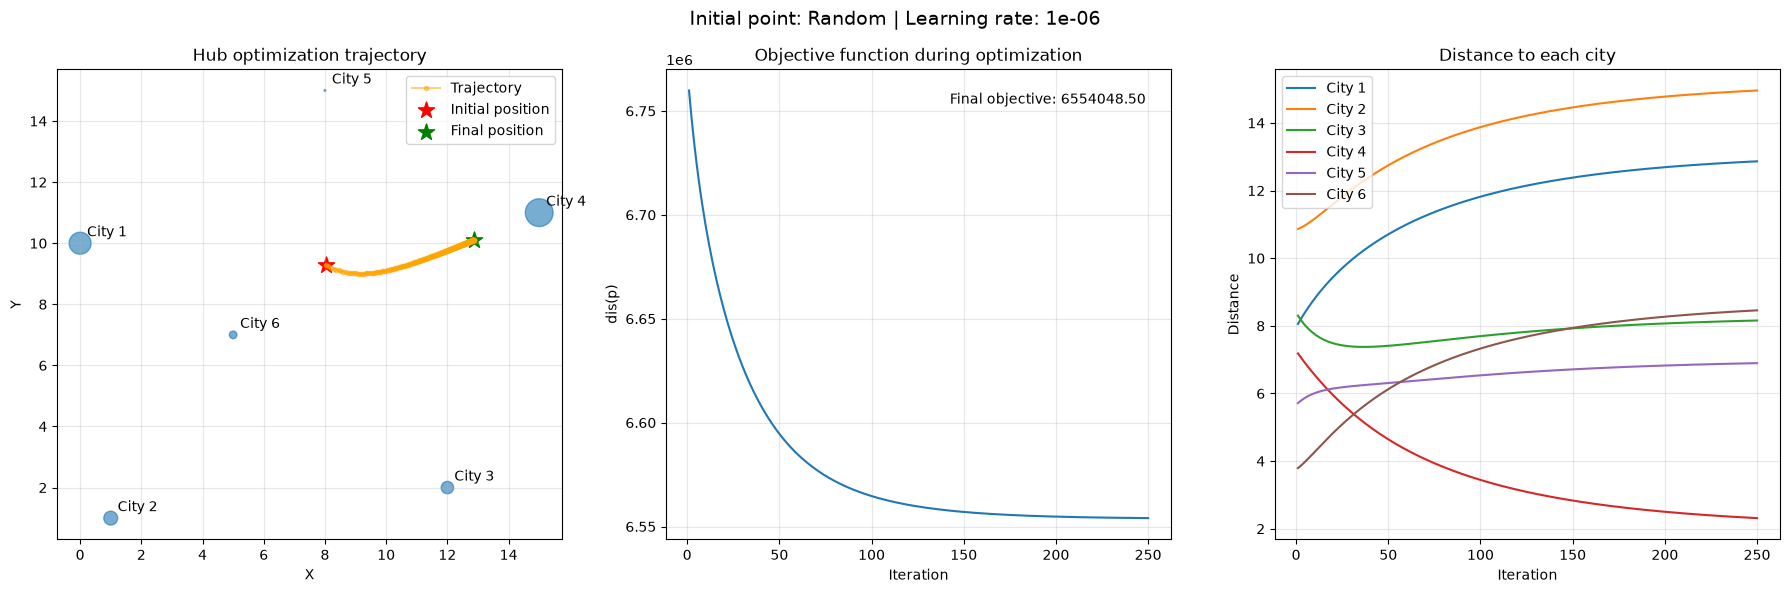

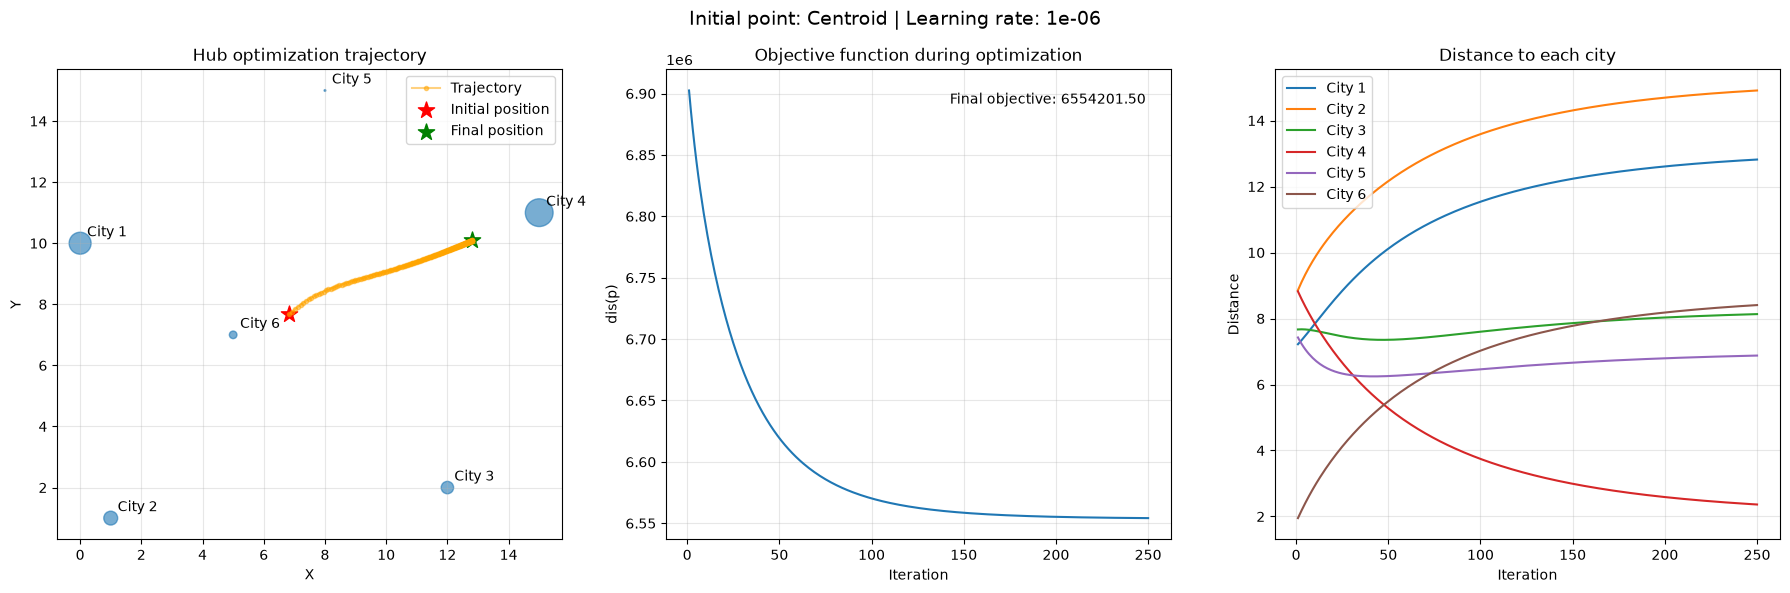

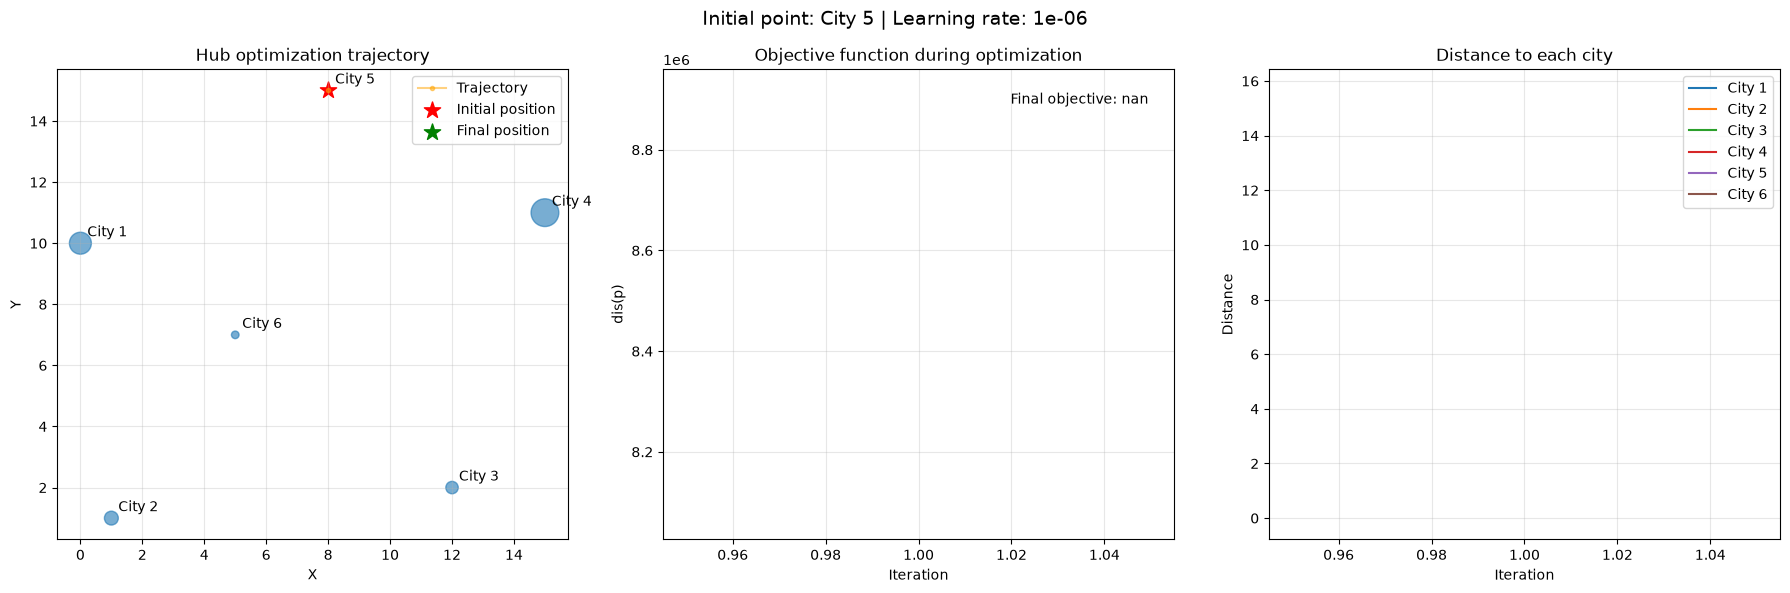

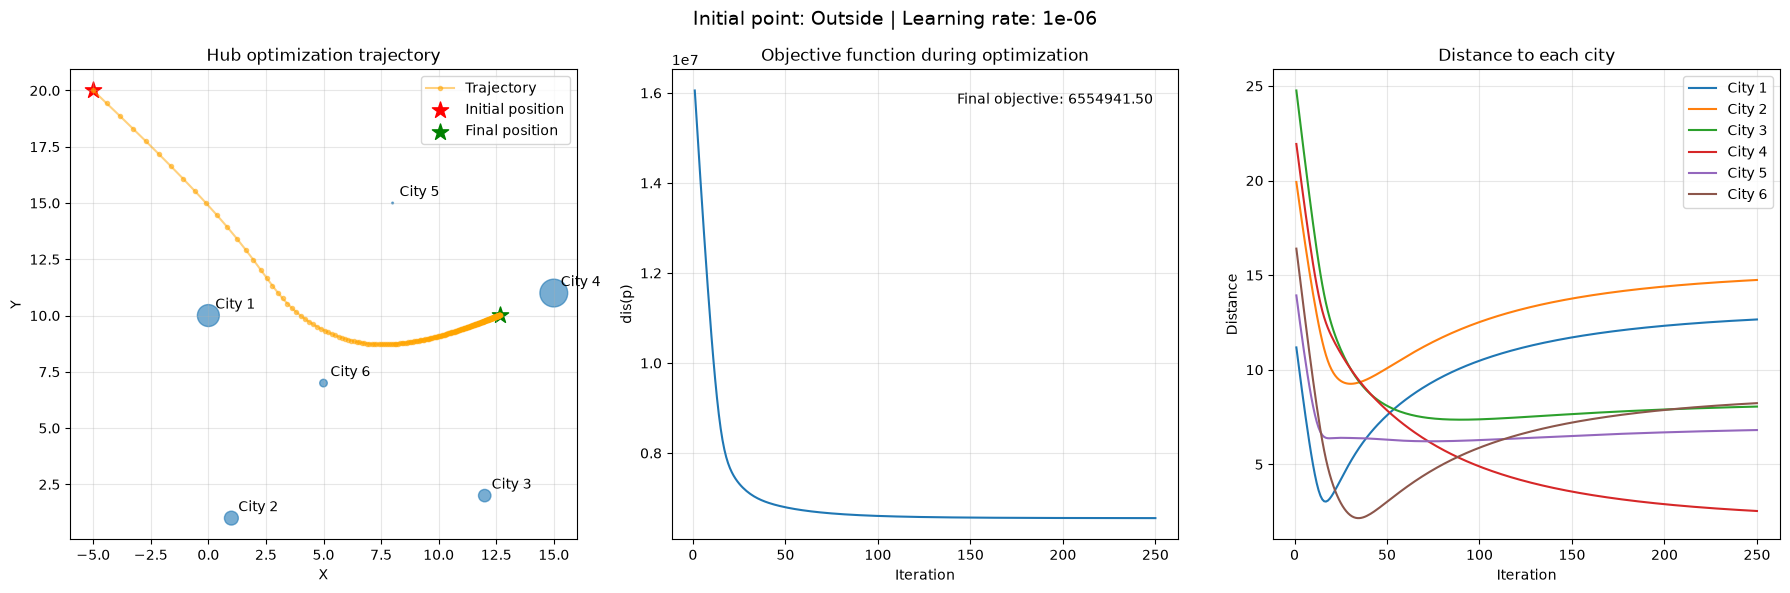

In [13]:
positions, loss_history, distance_history = optimize(random_point, lr, num_iterations)
plot_optimization(positions, loss_history, distance_history, "Random", lr)

positions, loss_history, distance_history = optimize(centroid, lr, num_iterations)
plot_optimization(positions, loss_history, distance_history, "Centroid", lr)

positions, loss_history, distance_history = optimize(city_point, lr, num_iterations)
plot_optimization(positions, loss_history, distance_history, "City 5", lr)

positions, loss_history, distance_history = optimize(outside_point, lr, num_iterations)
plot_optimization(positions, loss_history, distance_history, "Outside", lr)

In [14]:
initial_points = {
    "Random": random_point,
    "Centroid": centroid,
    "City 5": city_point,
    "Outside": outside_point
}

In [15]:
lr_very_small = 0.0000001
lr_small = 0.000001
lr_large = 0.001

In [16]:
learning_rates = [lr_very_small, lr_small, lr_large]

Random - Learning rate: 1e-07


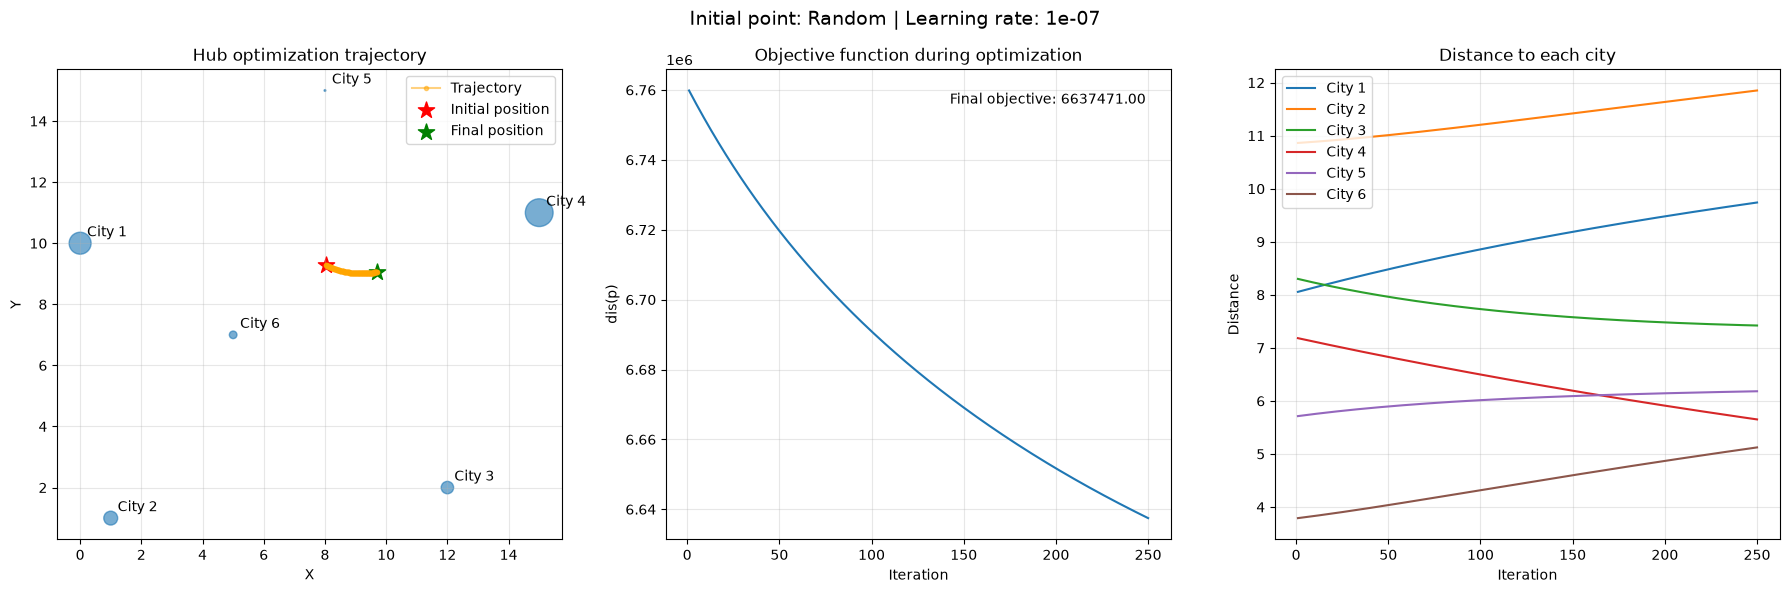

Centroid - Learning rate: 1e-07


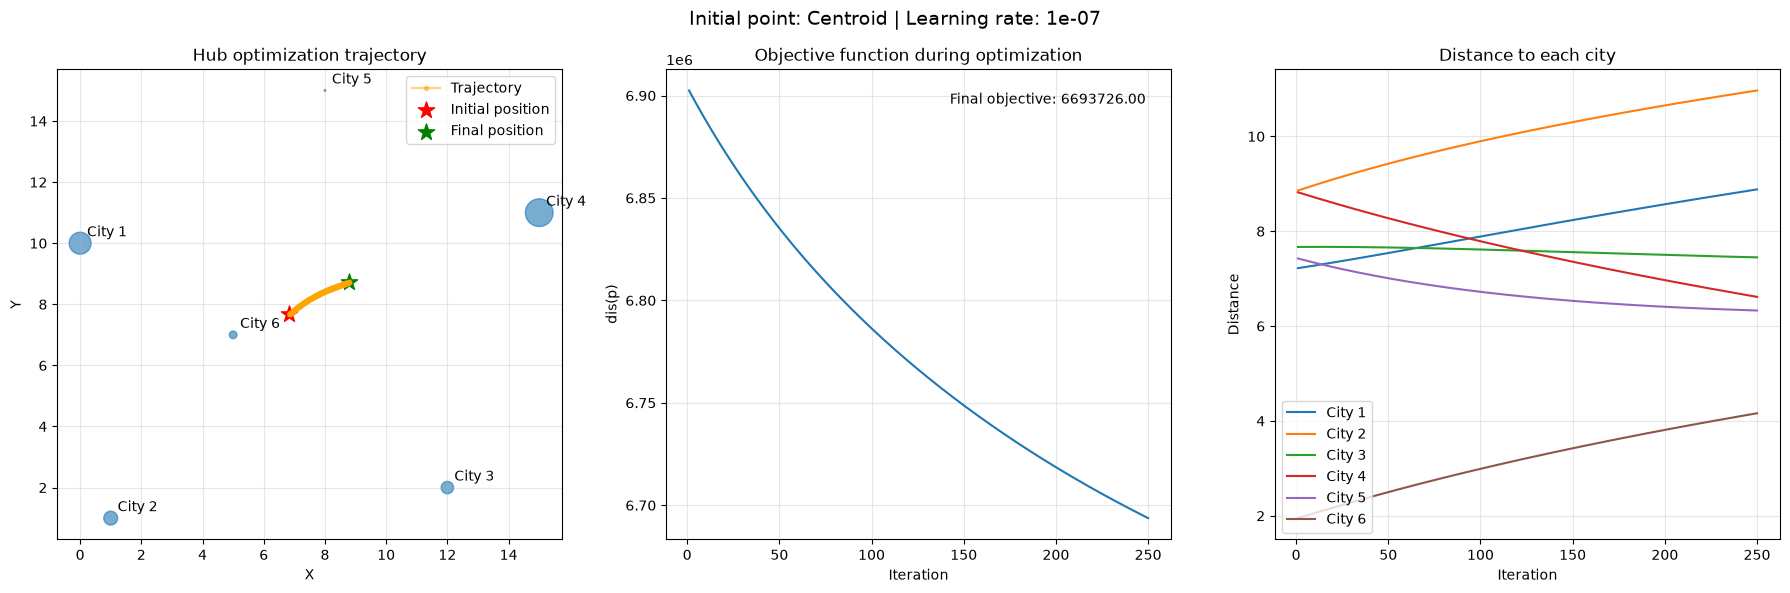

City 5 - Learning rate: 1e-07


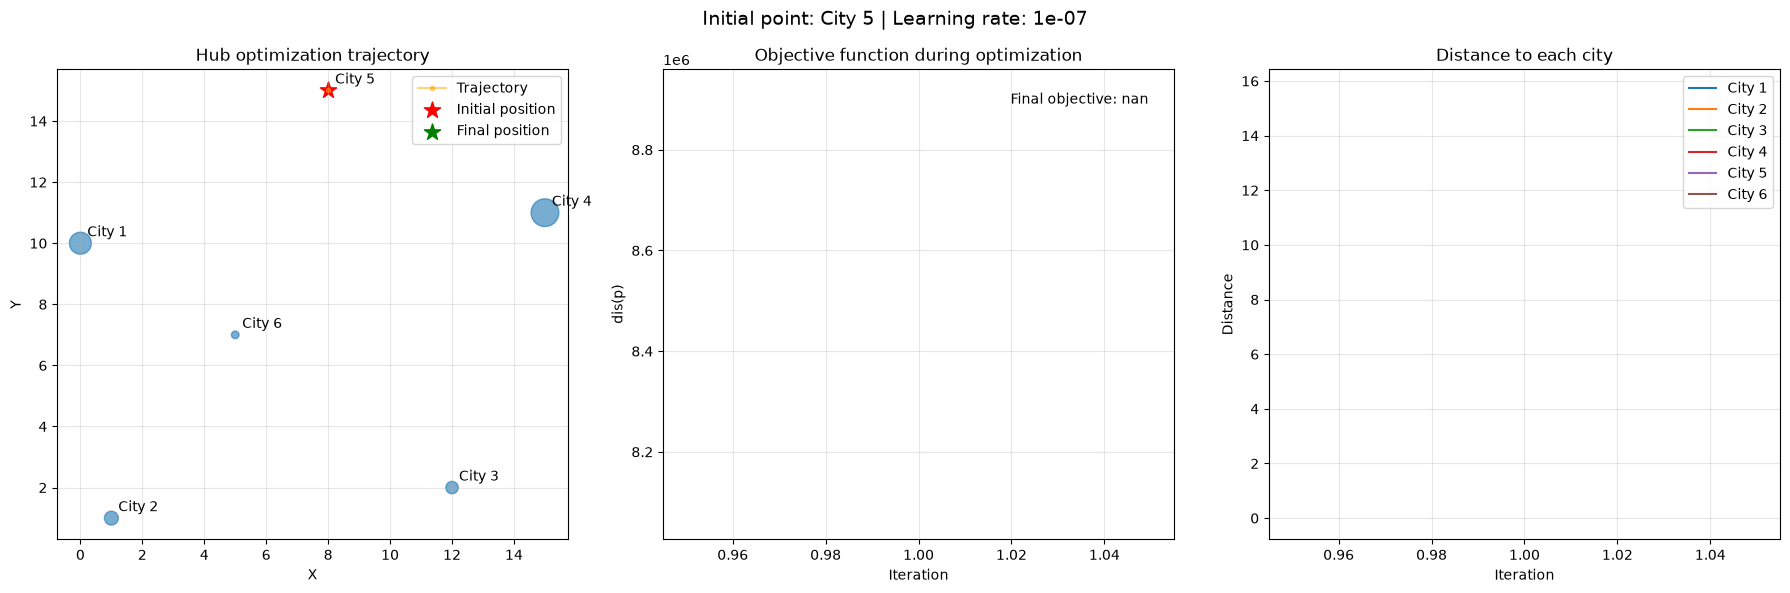

Outside - Learning rate: 1e-07


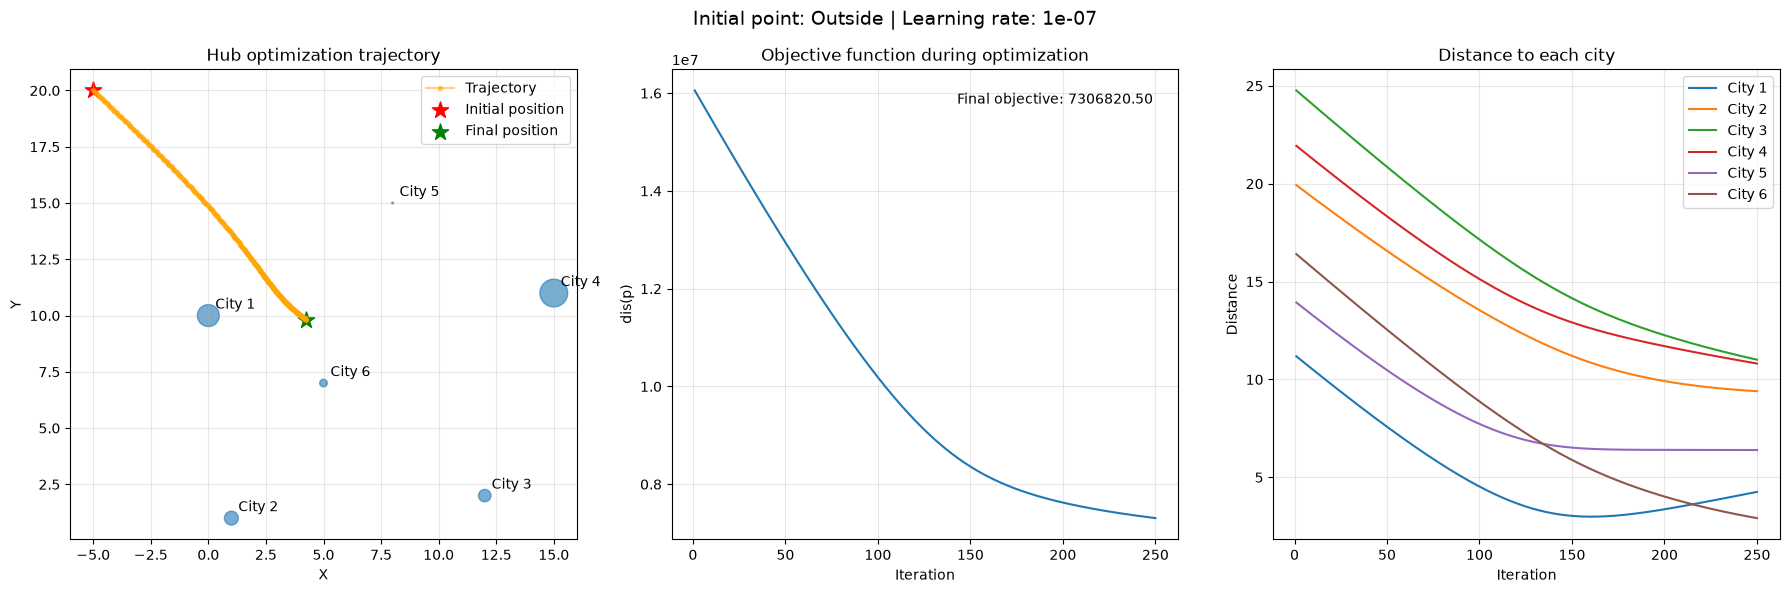

Random - Learning rate: 1e-06


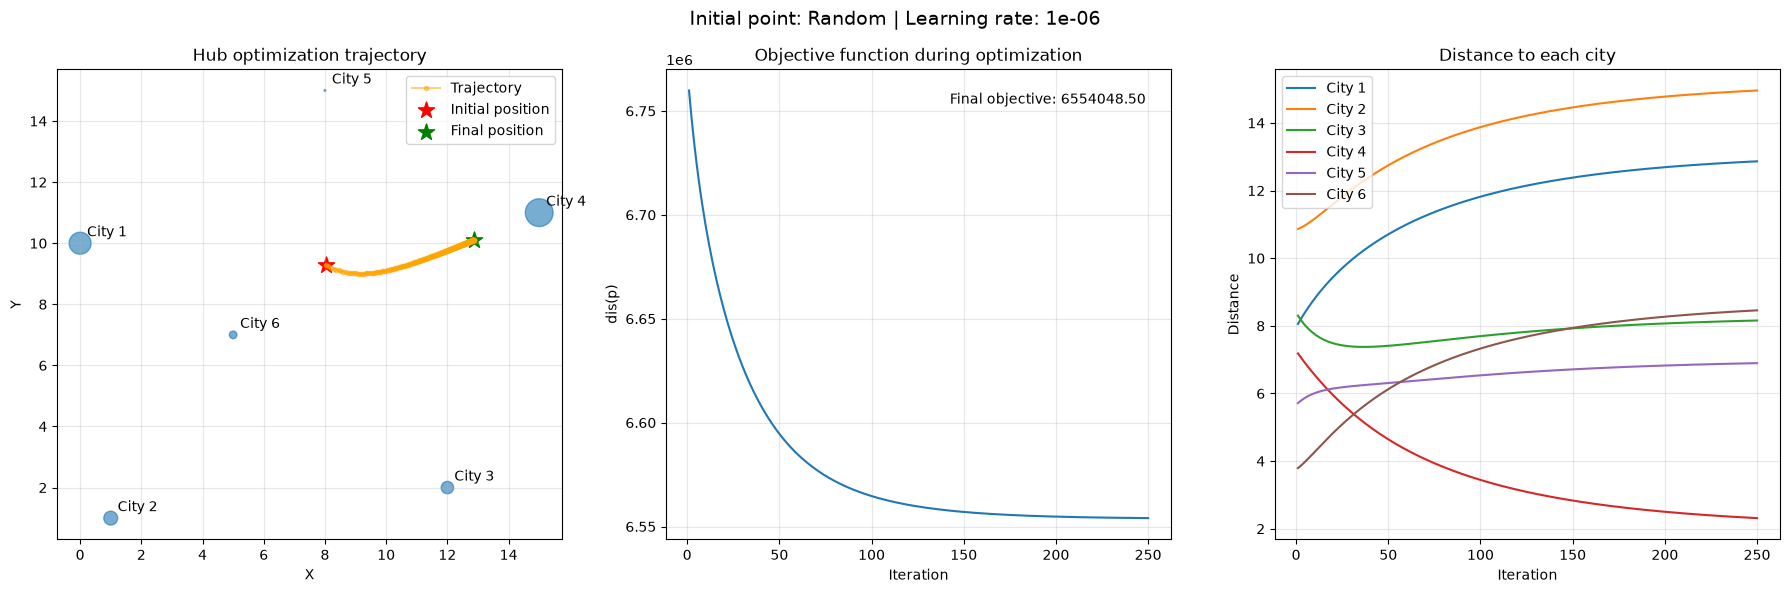

Centroid - Learning rate: 1e-06


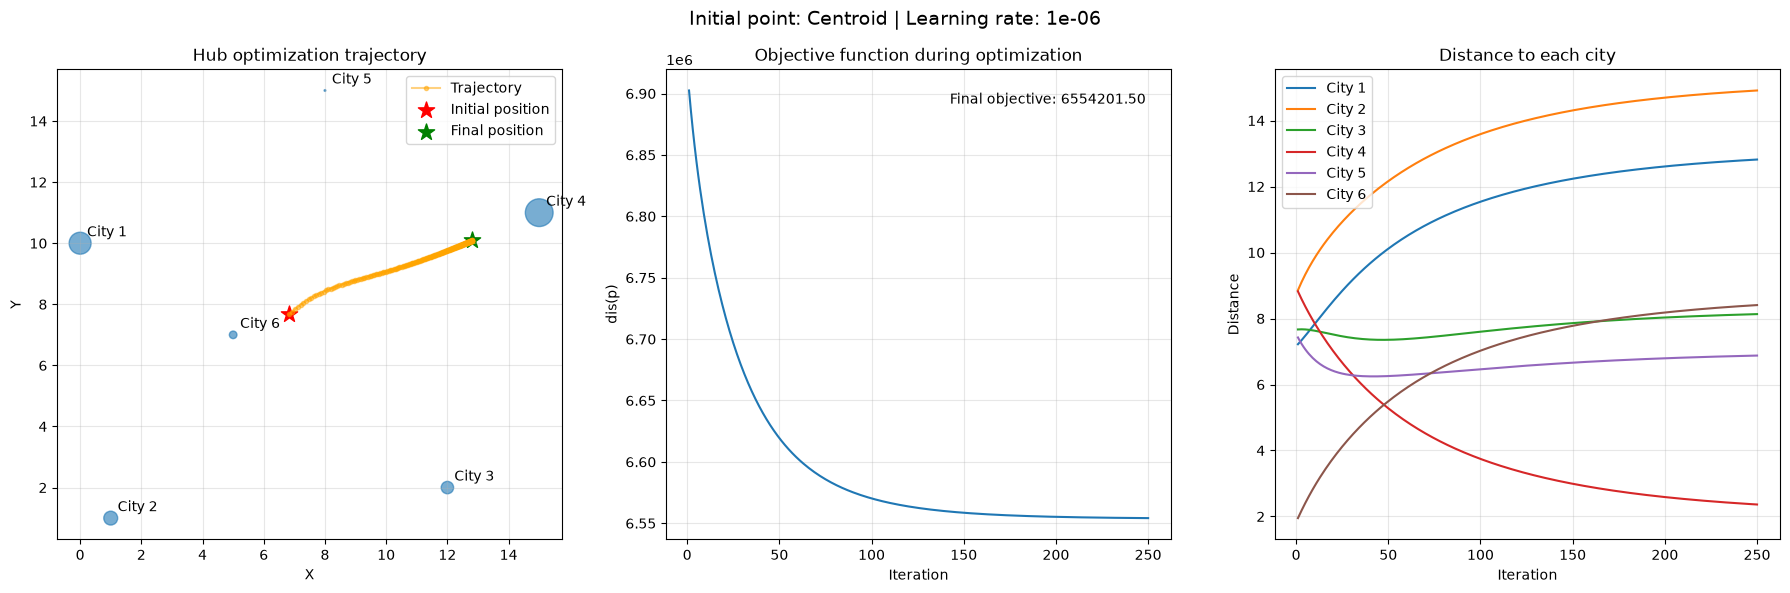

City 5 - Learning rate: 1e-06


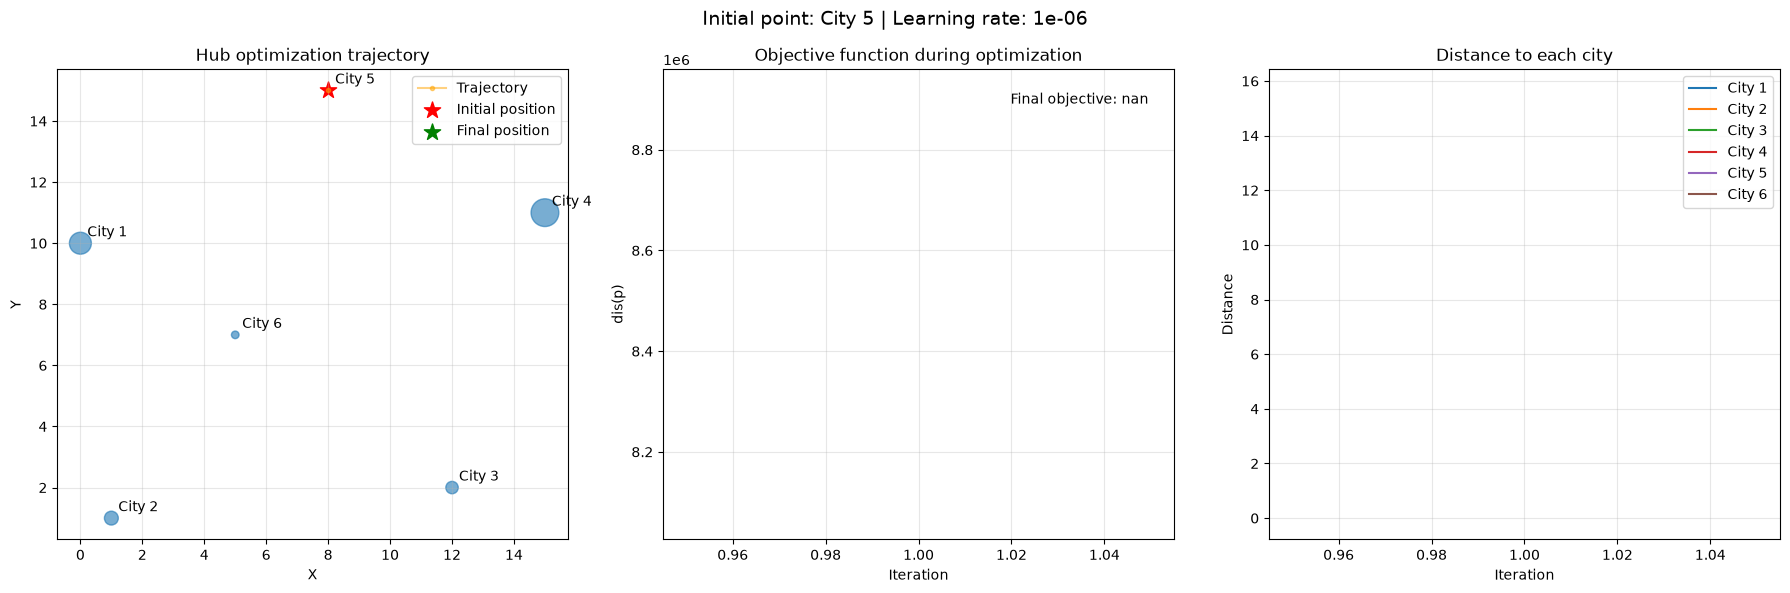

Outside - Learning rate: 1e-06


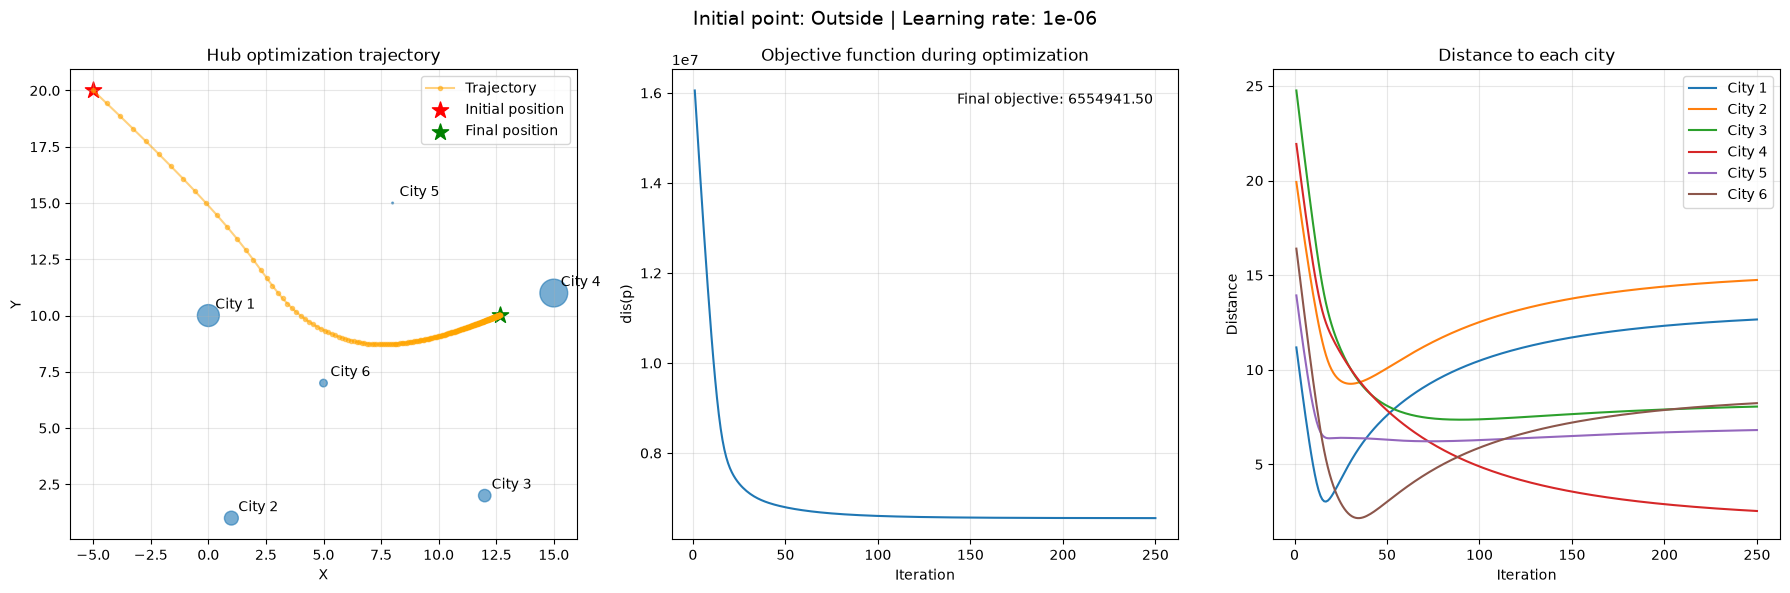

Random - Learning rate: 0.001


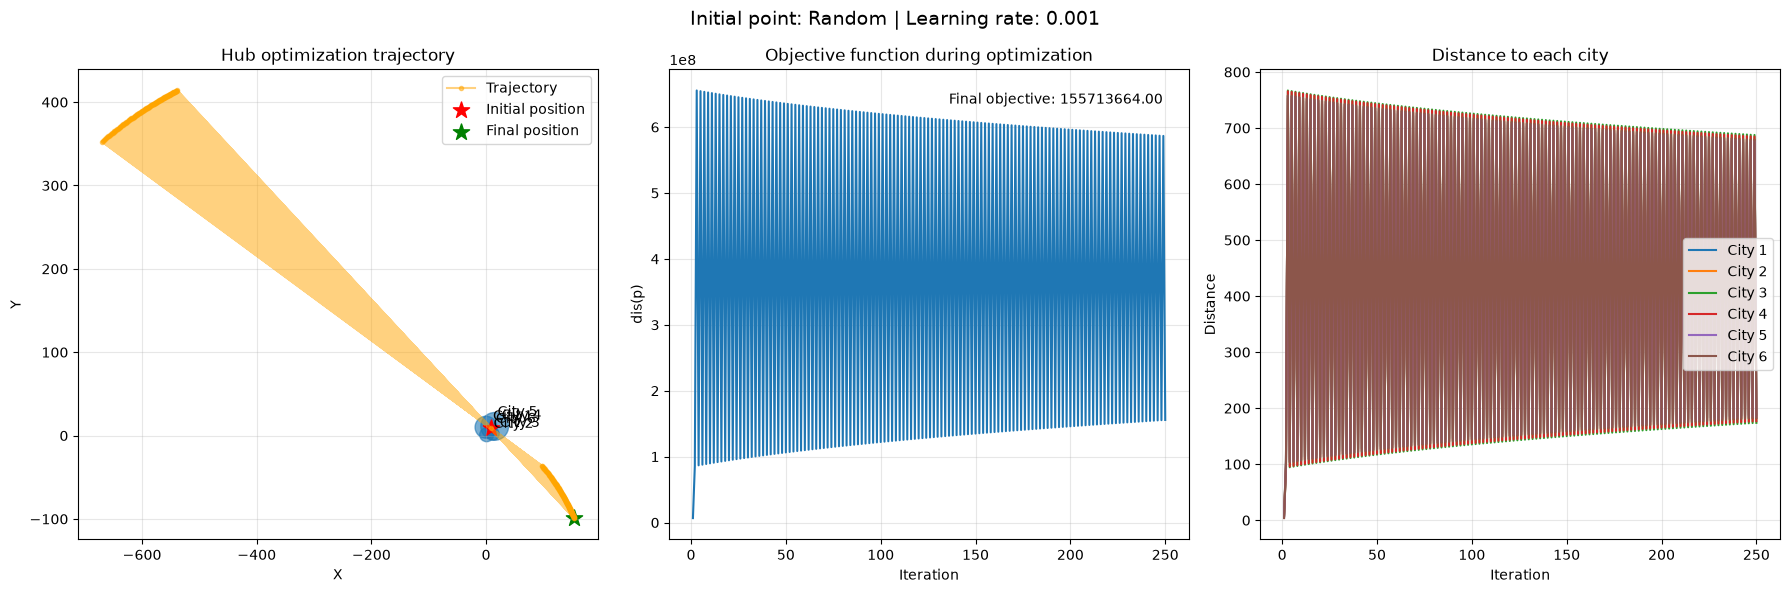

Centroid - Learning rate: 0.001


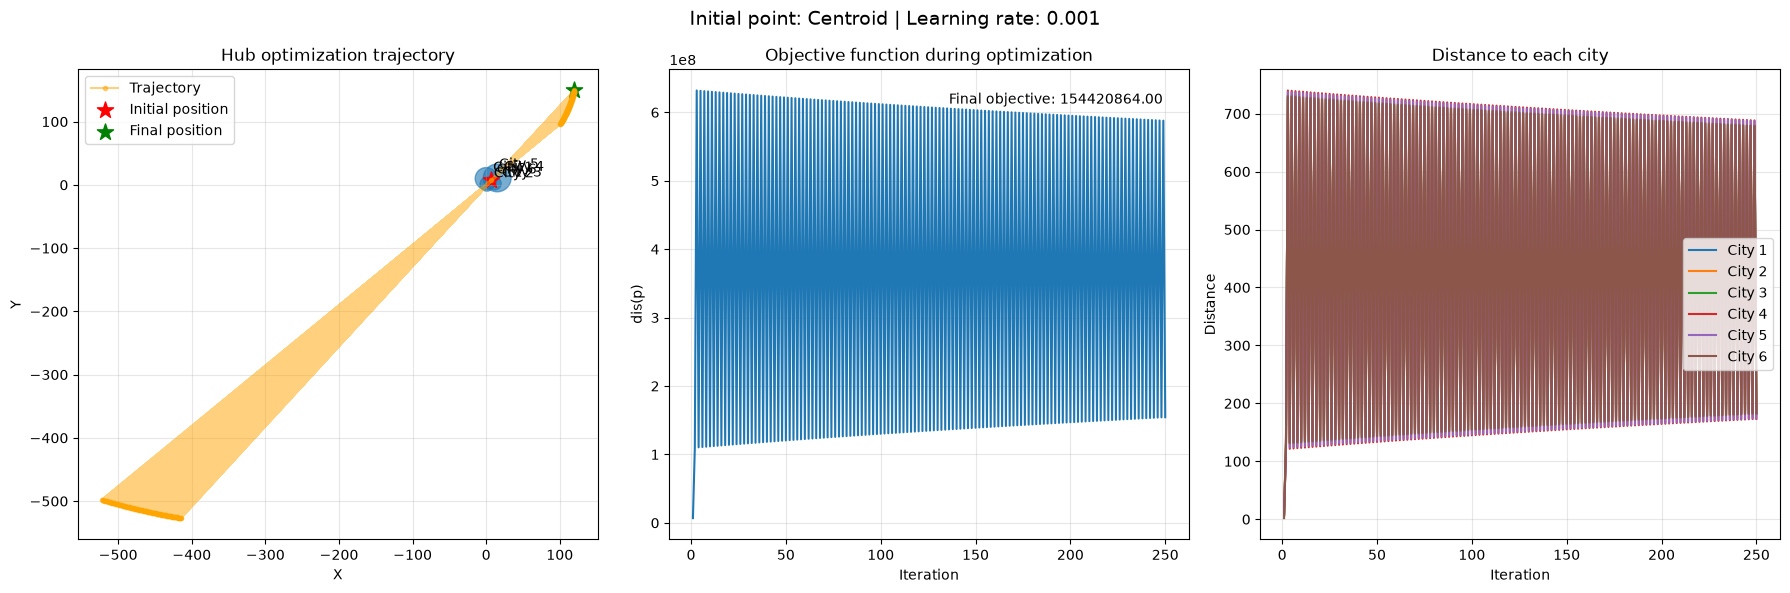

City 5 - Learning rate: 0.001


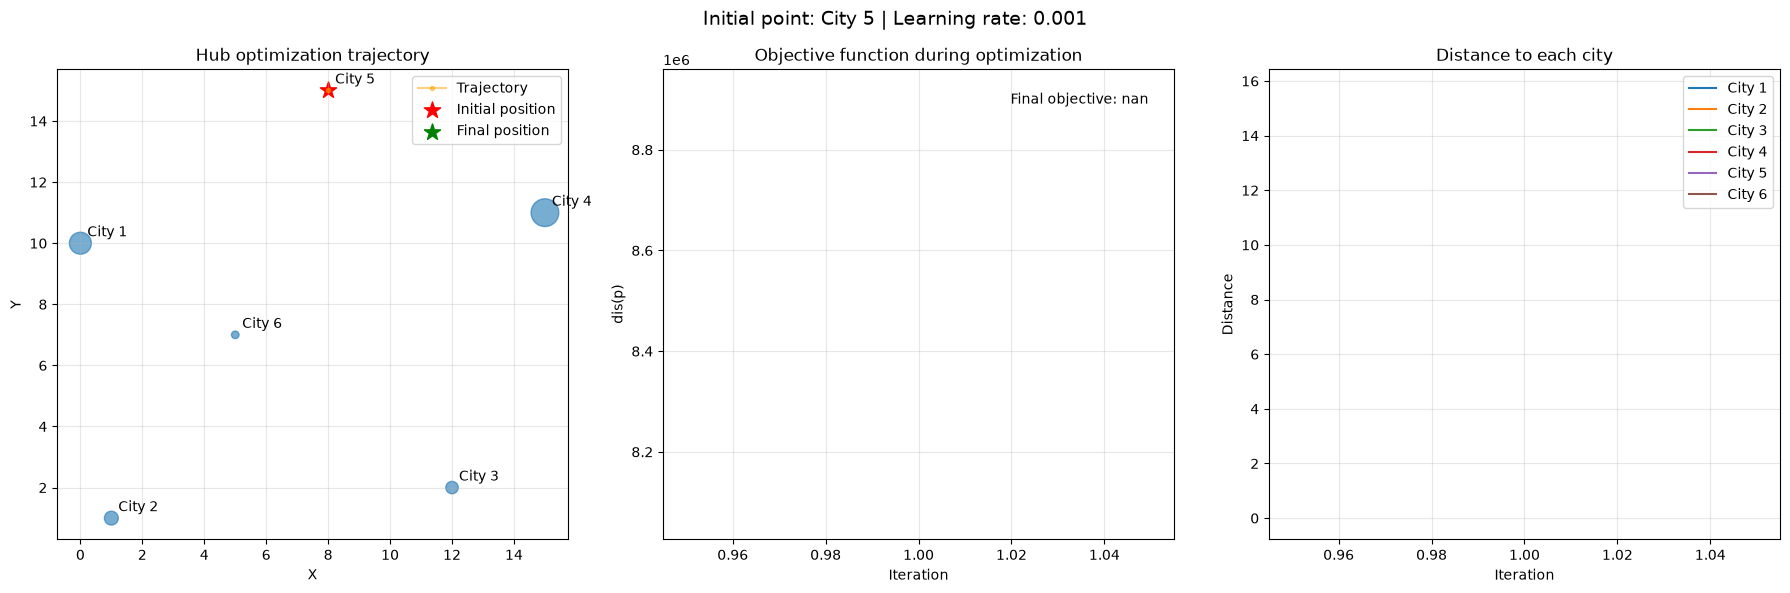

Outside - Learning rate: 0.001


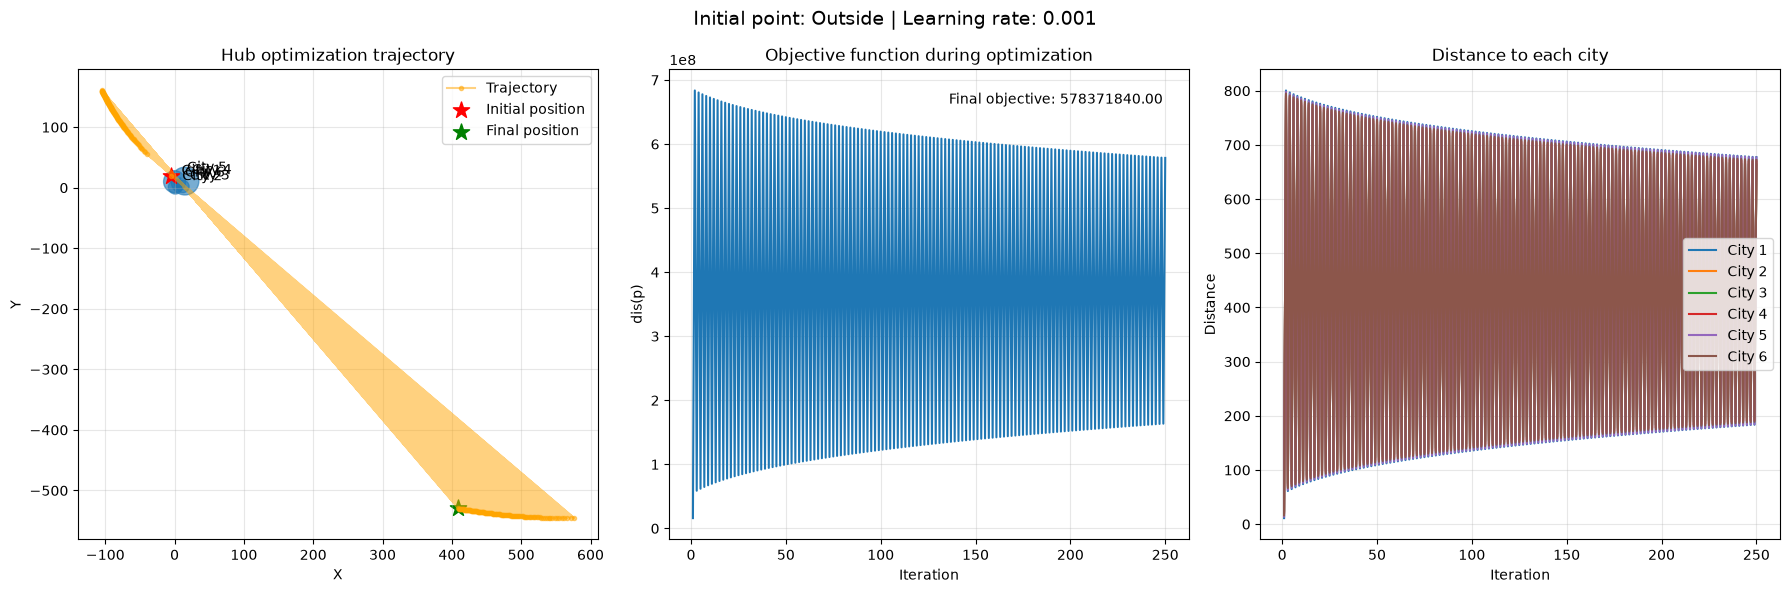

In [17]:
for lr in learning_rates:
    for initial_name, initial_point in initial_points.items():
        print(f"{initial_name} - Learning rate: {lr}")

        positions, loss_history, distance_history = optimize(initial_point, lr, num_iterations)

        plot_optimization(positions, loss_history, distance_history,initial_name, lr)

# TensorFlowwwyeea

In [18]:
c_tf = tf.constant([[0.0, 10.0],[1.0, 1.0], [12.0, 2.0],[15.0, 11.0],[8.0, 15.0],[5.0, 7.0]])

w_tf = tf.constant([250000.0,100000.0,80000.0,400000.0,1500.0,30000.0])

def dis_tf(p):
    distances = tf.sqrt(tf.reduce_sum((c_tf - p) ** 2, axis=1)) #same but with tf just in caseeee
    return tf.reduce_sum(w_tf * distances)

p_tf = tf.Variable([6.0, 8.0])

with tf.GradientTape() as tape:
    result_p = dis_tf(p_tf)

print("Result:", result_p.numpy())

gradient = tape.gradient(result_p, p_tf)

print("Point:", p_tf.numpy())
print("Gradient:", gradient.numpy())

learning_rate = 0.000001
p_tf.assign_sub(learning_rate * gradient)

print("Point:", p_tf.numpy())


E0000 00:00:1789506450.225141    6332 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1789506450.269819    6332 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Result: 6.968274e+06
Point: [6. 8.]
Gradient: [-119946.08   -47835.227]
Point: [6.119946 8.047835]


In [19]:
def optimize_tf(initial_point, learning_rate, iterations):
    positions = []
    loss_history = []
    distance_history = []

    p_tf = tf.Variable(initial_point, dtype=tf.float32)

    for i in range(iterations):

        with tf.GradientTape() as tape:
            result_p = dis_tf(p_tf)

        gradient = tape.gradient(result_p, p_tf)

        positions.append(p_tf.numpy().copy())

        loss_history.append(result_p.numpy())

        distances = tf.sqrt(tf.reduce_sum((c_tf - p_tf) ** 2, axis=1))
        distance_history.append(distances.numpy())

        p_tf.assign_sub(learning_rate * gradient)

    return positions, loss_history, distance_history

In [20]:
def plot_optimization_tf(positions, loss_history, distance_history, initial_name, learning_rate):

    positions = np.array(positions)
    loss_history = np.array(loss_history)
    distance_history = np.array(distance_history)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    #hub trajectory
    ax[0].scatter(x, y, s=city_size, alpha=0.6)

    for ciudad, xi, yi in zip(cities, x, y):
        ax[0].annotate(ciudad, (xi, yi), xytext=(5, 5), textcoords="offset points")

    ax[0].plot(positions[:, 0], positions[:, 1], marker="o", markersize=3,
               color="orange", alpha=0.5, label="Trajectory")

    ax[0].scatter(positions[0, 0], positions[0, 1], marker="*", s=150,
                  color="red", label="Initial position")

    ax[0].scatter(positions[-1, 0], positions[-1, 1], marker="*", s=150,
                  color="green", label="Final position")

    ax[0].set_xlabel("X")
    ax[0].set_ylabel("Y")
    ax[0].set_title("Hub optimization trajectory")
    ax[0].grid(True, alpha=0.3)
    ax[0].legend()

    #objective function
    ax[1].plot(range(1, len(loss_history) + 1), loss_history)

    final_loss = loss_history[-1]

    ax[1].set_xlabel("Iteration")
    ax[1].set_ylabel("dis(p)")
    ax[1].set_title("Objective function during optimization")
    ax[1].grid(True, alpha=0.3)

    ax[1].text(0.95, 0.95, f"Final objective: {final_loss:.2f}",
               transform=ax[1].transAxes, ha="right", va="top")

    #distance to eachh city
    for i in range(len(cities)):
        ax[2].plot(range(1, len(distance_history) + 1),
                   distance_history[:, i], label=cities[i])

    ax[2].set_xlabel("Iteration")
    ax[2].set_ylabel("Distance")
    ax[2].set_title("Distance to each city")
    ax[2].grid(True, alpha=0.3)
    ax[2].legend()

    #experiment information
    fig.suptitle(f"Initial point: {initial_name} | Learning rate: {learning_rate}",fontsize=14)

    plt.tight_layout()
    plt.show()

In [21]:
lr = 0.000001
num_iterations = 250

rpx = random.uniform(0, limit_x)
rpy = random.uniform(0, limit_y)

random_point_tf = tf.Variable([rpx, rpy], dtype=tf.float32)

positions_tf, loss_history_tf, distance_history_tf = optimize_tf(random_point_tf,lr,num_iterations)

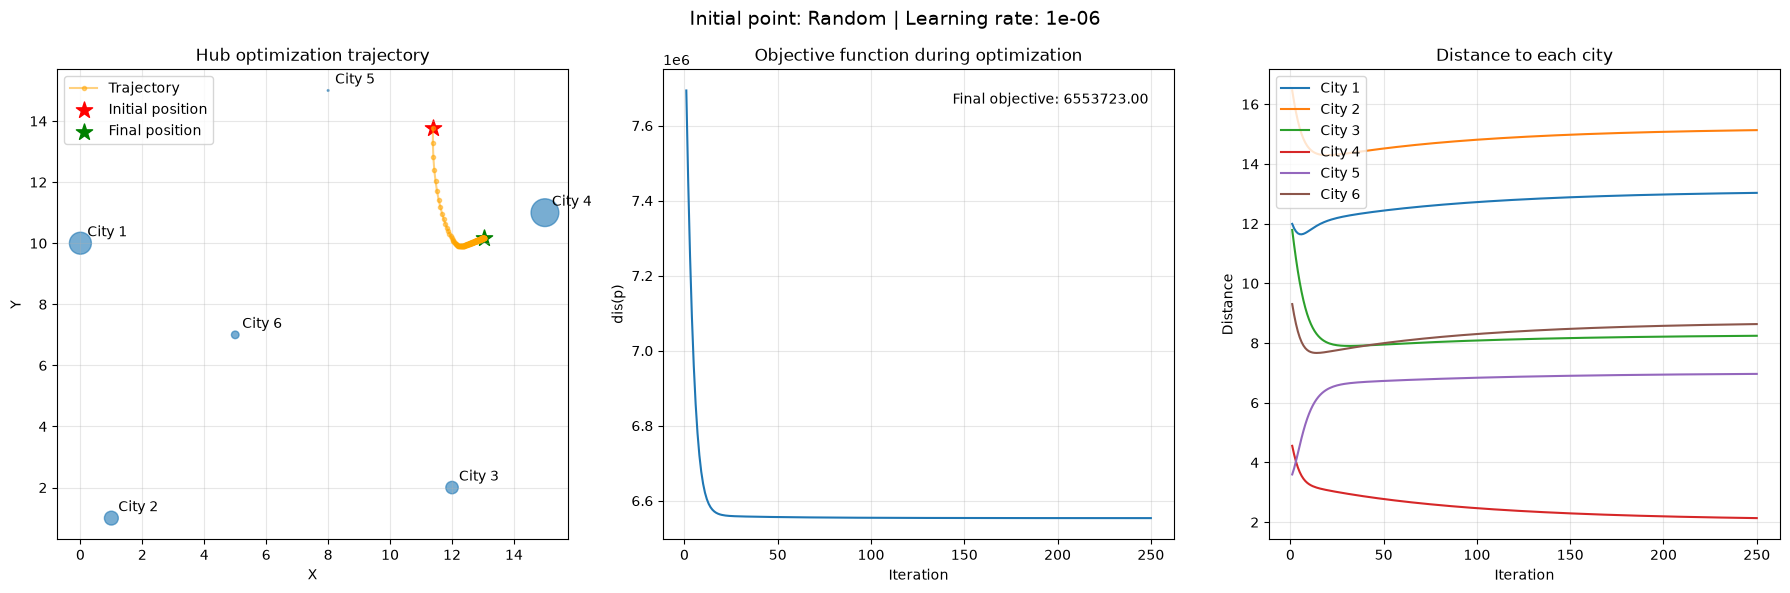

In [22]:
plot_optimization_tf(positions_tf,loss_history_tf,distance_history_tf,"Random",lr)

In [23]:
pytorch_times = []
tensorflow_times = []

for _ in range(10):
    start = time.perf_counter()
    optimize(random_point, 0.000001, 250)
    pytorch_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    optimize_tf(random_point_tf, 0.000001, 250)
    tensorflow_times.append(time.perf_counter() - start)

print(f"PyTorch average: {sum(pytorch_times) / len(pytorch_times):.6f} seconds")
print(f"TensorFlow average: {sum(tensorflow_times) / len(tensorflow_times):.6f} seconds")

PyTorch average: 0.125631 seconds
TensorFlow average: 0.877790 seconds
